In [1]:
#from bai_utils import *
from tbp_utils_2 import *
from experiments import sim_perf, sim_perf_deltas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns
from collections import defaultdict
from sklearn.preprocessing import normalize
import ipdb

In [2]:
def gen_data_bench(N=100, d=2, scale=1, sigma=1):

    theta = (2*np.random.rand(d)-1)
    theta = theta / np.linalg.norm(theta)
    theta = scale * theta
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,d).reshape(N, d)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    f = x @ theta
    y = np.random.normal(loc=f, scale=sigma)
    return x, y, theta

In [3]:
x, y, theta = gen_data_bench(N=100, d=2, scale=20)
deltas = [0.1,0.05,0.01,0.001]
T_max = 1000
N = 10
#d = 2
#x = np.eye(d)
rho = 0
epsilon = 0
eta = 0.15
print(np.min(np.abs(x @ theta-rho)))
x = x[np.abs(x @ theta - rho) > eta, :]

m, d = x.shape
prob_dict = {
    "m": m,
    "d": d,
    "x": x,
    "theta": theta,
}
prob = linear_discover(**prob_dict)

0.05794118932903958


In [4]:
np.min(np.abs(x @ theta-rho))

0.2510901723323409

(-1.020965372379813,
 1.0144609089176664,
 -1.5941468749119017,
 1.5941468749119017)

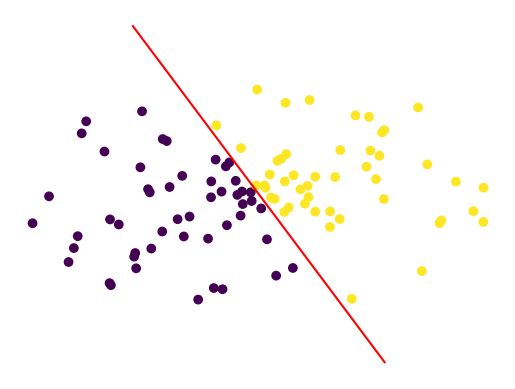

In [14]:
theta_ort = np.array([-theta[1]/13, theta[0]/13]) *np.linspace(-1,1,10)[:,None]
plt.scatter(x[:,0], x[:,1], c=x @ theta > 0)
plt.plot(theta_ort[:,0], theta_ort[:,1],c='r')
plt.axis('off')

#theta_ort

In [6]:
opt_desing = optimal_allocation(x, theta, rho, epsilon)[0]
algos_dict = {
    'linear_solver': [linear_solver, {'rho':rho, 'epsilon':epsilon}, 'linear_solver'],
  'Oracle_linear': [Oracle_linear, {'rho':rho, 'epsilon':epsilon, 'opt_desing':opt_desing}, 'Oracle_linear'],
  'lazy_TTS':      [lazy_TS, {'rho':rho, 'epsilon':epsilon}, 'lazy_TTS'],
  'LinGapE':       [LinGapE, {'rho':rho, 'epsilon':epsilon}, 'LinGapE'],
  'G_allocation':  [G_allocation_phase, {'rho':rho, 'epsilon':epsilon}, 'G_allocation'], 
  'rage':          [rage, {'rho':rho, 'epsilon':epsilon}, 'rage'],
  'LinGame':      [LinGame, {'rho':rho, 'epsilon':epsilon}, 'LinGame']
}

In [7]:
algos_res = defaultdict(list)
for algo, algo_setup in algos_dict.items():
    print(algo)
    prob_t = deepcopy(prob)
    algo_func, algo_params, name = algo_setup
    performance, performance_e, tau = sim_perf_deltas(algo_func, prob_t, algo_params, deltas, T_max=1000, N=10)
    algos_res[algo].append(performance)
    algos_res[algo].append(tau)

linear_solver


100%|█████████████████████████████████████████████| 4/4 [00:02<00:00,  1.59it/s]


Oracle_linear


100%|█████████████████████████████████████████████| 4/4 [00:00<00:00,  8.70it/s]


lazy_TTS


...

100%|█████████████████████████████████████████████| 4/4 [00:01<00:00,  3.19it/s]


rage


100%|█████████████████████████████████████████████| 4/4 [00:02<00:00,  1.78it/s]


LinGame


100%|█████████████████████████████████████████████| 4/4 [02:59<00:00, 44.86s/it]


In [21]:
df_sample_complex = pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()) for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()
df_sample_complex

,linear_solver,Oracle_linear,lazy_TTS,LinGapE,G_allocation,rage,LinGame
0.100,522.800000,66.5,78.5,61.1,136.1,200.0,137.9
0.050,561.900000,70.3,80.0,63.5,142.4,215.5,141.8
0.010,642.600000,76.3,90.5,71.4,166.5,248.0,161.6
0.001,699.777778,84.2,111.8,93.7,218.0,288.8,191.8


In [8]:
df_sample_complex = pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()) for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()
df_sample_complex

,linear_solver,Oracle_linear,lazy_TTS,LinGapE,G_allocation,rage,LinGame
0.100,504.3,64.3,56.5,63.2,85.4,171.5,85.0
0.050,525.7,68.4,69.4,67.1,97.0,182.3,89.7
0.010,591.9,74.4,75.8,77.8,111.8,205.2,95.3
0.001,699.8,84.9,90.7,76.6,139.9,247.5,104.4


In [11]:
df_correct = pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][0]).mean()) for algo, algo_setup in algos_dict.items()], axis=1)
df_correct.columns = algos_dict.keys()
df_correct

,linear_solver,Oracle_linear,lazy_TTS,LinGapE,G_allocation,rage,LinGame
0.100,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0.050,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0.010,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0.001,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
deltas = [0.05]
T_max = 1000
N = 10
d = 2
x = np.eye(d)
rho = 5#10*np.cos(alpha1)
alpha1 = .1#np.pi/4 + .2
alpha2 = -.1#6/4*np.pi+np.pi/4 + .2
x = np.concatenate([x, 
                    .55*(np.cos(alpha1) * x[0:1] + np.sin(alpha1) * x[1:2]),
                    .45*(np.cos(alpha2) * x[0:1] + np.sin(alpha2) * x[1:2])])
#x = np.concatenate([x, (x[0:1]*(1/2+0.05) + x[1:2]*(1/2-0.05) )])#+ x[2:3]*(1/3))])
theta = 10*x[0]
x @ theta
epsilon = 0.05
m, d = x.shape
prob_dict = {
    "m": m,
    "d": d,
    "x": x,
    "theta": theta,
}
prob = linear_discover(**prob_dict)
x, x @ theta

(array([[ 1.        ,  0.        ],
        [ 0.        ,  1.        ],
        [ 0.54725229,  0.05490838],
        [ 0.44775187, -0.04492504]]),
 array([10.        ,  0.        ,  5.47252291,  4.47751874]))

In [8]:
(5.17402166+  4.77601999)/2

4.975020825

(-0.07, 1.09)

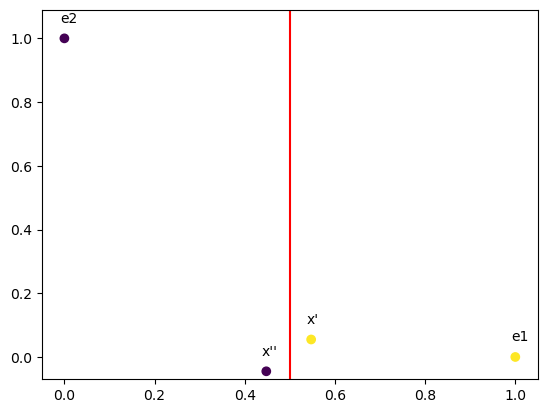

In [34]:
plt.scatter(x[:,0], x[:,1], c=x @ theta>5)
plt.annotate('e1', (x[0,0], x[0,1]),xytext=(x[0,0]-0.01, x[0,1]+0.05))
plt.annotate('e2', (x[1,0], x[1,1]),xytext=(x[1,0]-0.01, x[1,1]+0.05))
plt.annotate("x'", (x[2,0], x[2,1]),xytext=(x[2,0]-0.01, x[2,1]+0.05))
plt.annotate("x''", (x[3,0], x[3,1]),xytext=(x[3,0]-0.01, x[3,1]+0.05))
plt.vlines(x=.5, ymin=-0.07, ymax=1.09,color='r')
plt.ylim(-0.07,1.09)

In [4]:
opt_desing = optimal_allocation(x, theta, rho, epsilon)[0]
algos_dict = {
  'linear_solver': [linear_solver, {'rho':rho, 'epsilon':epsilon}, 'linear_solver'],
  'Oracle_linear': [Oracle_linear, {'rho':rho, 'epsilon':epsilon, 'opt_desing':opt_desing}, 'Oracle_linear'],
  'lazy_TTS':      [lazy_TS, {'rho':rho, 'epsilon':epsilon}, 'lazy_TTS'],
  'LinGapE':       [LinGapE, {'rho':rho, 'epsilon':epsilon}, 'LinGapE'],
  'G_allocation':  [G_allocation_phase, {'rho':rho, 'epsilon':epsilon}, 'G_allocation'], 
  'rage':          [rage, {'rho':rho, 'epsilon':epsilon}, 'rage']    
}

In [5]:
algos_res = defaultdict(list)
for algo, algo_setup in algos_dict.items():
    print(algo)
    prob_t = deepcopy(prob)
    algo_func, algo_params, name = algo_setup
    performance, performance_e, tau = sim_perf_deltas(algo_func, prob_t, algo_params, deltas, T_max=10000, N=100)
    algos_res[algo].append(performance)
    algos_res[algo].append(tau)

linear_solver


100%|█████████████████████████████████████████████| 4/4 [00:12<00:00,  3.21s/it]


Oracle_linear


100%|█████████████████████████████████████████████| 4/4 [00:03<00:00,  1.05it/s]


lazy_TTS


...

100%|█████████████████████████████████████████████| 4/4 [00:49<00:00, 12.36s/it]


G_allocation


100%|█████████████████████████████████████████████| 4/4 [00:14<00:00,  3.56s/it]


rage


100%|█████████████████████████████████████████████| 4/4 [00:23<00:00,  5.76s/it]


In [6]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,Oracle_linear,lazy_TTS,LinGapE,G_allocation,rage
0.100,251.09,54.19,53.92,65.28,105.23,167.47
0.050,272.40,58.77,58.28,69.81,112.16,175.10
0.010,308.75,67.11,67.14,78.00,127.60,196.00
0.001,355.63,79.39,78.15,91.38,146.92,227.44


In [7]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,Oracle_linear,lazy_TTS,LinGapE,G_allocation,rage
0.100,98.497818,23.233855,24.401805,25.587276,46.057903,20.223726
0.050,102.908315,25.794391,25.788213,26.450142,48.496948,19.179377
0.010,109.601240,27.730265,28.598234,27.772525,51.516007,20.257933
0.001,119.328395,29.561747,29.999790,28.577656,52.785956,24.410761


In [26]:
df_correct = pd.concat([pd.DataFrame((pd.DataFrame(algos_res[algo][0])).mean()) for algo, algo_setup in algos_dict.items()], axis=1)
df_correct.columns = algos_dict.keys()
df_correct

,linear_solver,Oracle_linear,lazy_TTS,LinGapE,G_allocation,rage
0.05,0.0,0.0,0.0,0.0,0.0,0.0


In [97]:
N = 1000
probs = defaultdict(list)
for d in [2,5,10,20]:
    for i in range(N):
        #d = 5
        x = np.eye(d)
        rho = 5#10*np.cos(alpha1)
        alpha1 = .1#np.pi/4 + .2
        alpha2 = -.1#6/4*np.pi+np.pi/4 + .2
        x = np.concatenate([x, 
                            .55*(np.cos(alpha1) * x[0:1] + np.sin(alpha1) * x[1:2]),
                            .45*(np.cos(alpha2) * x[0:1] + np.sin(alpha2) * x[1:2])])
        #x = np.concatenate([x, (x[0:1]*(1/2+0.05) + x[1:2]*(1/2-0.05) )])#+ x[2:3]*(1/3))])
        theta = 10*x[0]
        x @ theta
        epsilon = 0
        m, d = x.shape
        prob_dict = {
            "m": m,
            "d": d,
            "x": x,
            "theta": theta,
        }
        prob = linear_discover(**prob_dict)
        probs[d].append(prob)

In [98]:
opt_desing = optimal_allocation(x, theta, rho, epsilon)[0]
algos_dict = {
  'linear_solver': [linear_solver, {'rho':rho, 'epsilon':epsilon}, 'linear_solver'],
  #'lazy_TTS':      [lazy_TS, {'rho':rho, 'epsilon':epsilon}, 'lazy_TTS'],
  #'LinGapE':       [LinGapE, {'rho':rho, 'epsilon':epsilon}, 'LinGapE'],
  #'G_allocation':  [G_allocation_phase, {'rho':rho, 'epsilon':epsilon}, 'G_allocation'], 
  #'rage':          [rage, {'rho':rho, 'epsilon':epsilon}, 'rage'],
  #'LinGame':      [LinGame, {'rho':rho, 'epsilon':epsilon}, 'LinGame']
}

In [99]:
algos_res = defaultdict(list)
for algo, algo_setup in algos_dict.items():
    print(algo)
    probs_t = deepcopy(probs)
    algo_func, algo_params, name = algo_setup
    performance, performance_e, tau = sim_perf(algo_func, probs_t, algo_params, 0.05, T_max=10000, N=1000)
    algos_res[algo].append(performance)
    algos_res[algo].append(tau)

linear_solver


100%|████████████████████████████████████████████| 4/4 [10:03<00:00, 150.81s/it]


In [120]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver
2,93.274
5,299.790
10,1027.675
20,3718.428


In [121]:
test_pd = pd.DataFrame(algos_res[algo][1]).reset_index()
test_pd['index'] = (test_pd['index']%10)
test_pd.groupby('index').mean().std()

2      2.756899
5      7.920595
10    23.031370
20    40.858423
dtype: float64

In [122]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex / np.sqrt(100)

,linear_solver
2,2.780601
5,8.087649
10,22.148004
20,48.756636


In [101]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver
2,27.806008
5,80.876492
10,221.480037
20,487.566358


In [16]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage,LinGame
2,73.9,37.8,46.6,56.3,42.6,39.6
3,88.7,42.1,57.6,122.2,63.1,53.3
4,130.6,49.5,63.9,198.0,160.6,63.6


In [29]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
2,73.9,37.8,49.3,56.3,42.6
3,88.7,42.1,55.5,122.2,63.1
4,130.6,49.5,69.3,198.0,160.6


In [30]:
print(df_sample_complex.to_latex(index=True,
                  formatters={"name": str.upper},
                  float_format="{:.2f}".format,
)) 

\begin{tabular}{lrrrrr}
\toprule
{} &  linear\_solver &  lazy\_TTS &  LinGapE &  G\_allocation &   rage \\
\midrule
2 &          73.90 &     37.80 &    49.30 &         56.30 &  42.60 \\
3 &          88.70 &     42.10 &    55.50 &        122.20 &  63.10 \\
4 &         130.60 &     49.50 &    69.30 &        198.00 & 160.60 \\
\bottomrule
\end{tabular}



/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_27914/3709730982.py:1: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  print(df_sample_complex.to_latex(index=True,


In [17]:
df_correct = pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][0]).mean()) for algo, algo_setup in algos_dict.items()], axis=1)
df_correct.columns = algos_dict.keys()
df_correct

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage,LinGame
2,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0


In [87]:
N = 100
K_list = [105,209,315,525,1050]
probs = defaultdict(list)
for K in K_list: 
    for i in range(N):
        x, y, theta = gen_data_bench(K, d=2, scale=10)
        #d = 2
        #x = np.eye(d)
        rho = 0.5
        epsilon = 0
        eta = 0.15
        x = x[np.abs(x @ theta - rho) > eta, :]
        #print(np.min(np.abs(x @ theta-rho)))

        m, d = x.shape
        prob_dict = {
            "m": m,
            "d": d,
            "x": x,
            "theta": theta,
        }
        prob = linear_discover(**prob_dict)
        probs[K].append(prob)


In [88]:
[np.mean([probs[K][i].x.shape[0] for i in range(50)]) for K in K_list]

[101.44, 201.08, 303.68, 506.34, 1013.08]

In [89]:
[np.min([np.min(np.abs(prob.x @ prob.theta-rho)) for prob in prob_list]) for K, prob_list in probs.items()]

[0.15078688642188087,
 0.15055801723743584,
 0.1500616163658166,
 0.15015255645116965,
 0.15002868491161503]

In [36]:
opt_desing = optimal_allocation(x, theta, rho, epsilon)[0]
algos_dict = {
  'linear_solver': [linear_solver, {'rho':rho, 'epsilon':epsilon}, 'linear_solver'],
  #'lazy_TTS':      [lazy_TS, {'rho':rho, 'epsilon':epsilon}, 'lazy_TTS'],
  #'LinGapE':       [LinGapE, {'rho':rho, 'epsilon':epsilon}, 'LinGapE'],
  #'G_allocation':  [G_allocation_phase, {'rho':rho, 'epsilon':epsilon}, 'G_allocation'], 
  #'rage':          [rage, {'rho':rho, 'epsilon':epsilon}, 'rage'],
  #'LinGame':      [LinGame, {'rho':rho, 'epsilon':epsilon}, 'LinGame']
}

In [64]:
#[100,200,300,500,1000]


[96.54, 193.06, 289.38, 481.36, 965.38]

In [90]:
algos_res = defaultdict(list)
for algo, algo_setup in algos_dict.items():
    print(algo)
    probs_t = deepcopy(probs)
    algo_func, algo_params, name = algo_setup
    performance, performance_e, tau = sim_perf(algo_func, probs_t, algo_params, 0.05, T_max=10000, N=100)
    algos_res[algo].append(performance)
    algos_res[algo].append(tau)

linear_solver


100%|█████████████████████████████████████████████| 5/5 [03:40<00:00, 44.07s/it]


In [15]:
algos_res_ = defaultdict(list)
for algo, algo_setup in algos_dict.items():
    print(algo)
    probs_t = deepcopy(probs)
    algo_func, algo_params, name = algo_setup
    performance, performance_e, tau = sim_perf(algo_func, probs_t, algo_params, 0.05, T_max=10000, N=10)
    algos_res_[algo].append(performance)
    algos_res_[algo].append(tau)

linear_solver


100%|█████████████████████████████████████████████| 5/5 [00:19<00:00,  3.85s/it]


lazy_TTS


100%|████████████████████████████████████████████| 5/5 [12:54<00:00, 154.97s/it]


LinGapE


100%|█████████████████████████████████████████████| 5/5 [03:20<00:00, 40.03s/it]


G_allocation


100%|█████████████████████████████████████████████| 5/5 [00:08<00:00,  1.69s/it]


rage


 60%|███████████████████████████                  | 3/5 [00:03<00:02,  1.09s/it]/Users/eochoa/Documents/Research_Ambuj/M4AM/discovery_sampling/thresholding_bandit/tbp_utils_2.py:389: RuntimeWarning: invalid value encountered in sqrt
  norms = (np.sqrt(x[:,None] @ A_inv @ x[:,:,None]).flatten())
100%|█████████████████████████████████████████████| 5/5 [00:09<00:00,  1.86s/it]


In [91]:
df_sample_complex2 = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex2.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex2

,linear_solver
105,1609.930000
209,2284.860000
315,2805.707071
525,3814.560000
1050,4500.686869


In [29]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res_[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
100,1625.800000,283.6,318.0,479.0,433.3
200,2578.400000,387.8,481.8,711.6,678.0
300,4202.700000,475.4,599.1,1181.6,860.9
500,4117.125000,572.1,772.9,1339.4,984.4
1000,4159.888889,839.2,819.6,1506.5,1071.8


In [92]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver
105,1474.290908
209,1411.322297
315,1807.233974
525,2142.298536
1050,2038.622728


In [34]:
algos_res['lazy_TTS'][1]

defaultdict(list,
            {100: [846, 316, 338, 61, 90, 177, 285, 164, 40, 519],
             200: [179, 369, 395, 137, 135, 1696, 137, 309, 132, 389],
             300: [600, 855, 290, 562, 318, 573, 312, 423, 383, 438],
             500: [1246, 254, 605, 236, 968, 475, 371, 444, 306, 816],
             1000: [638, 1124, 965, 1004, 1025, 277, 400, 1021, 874, 1064]})

In [30]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
100,957.223740,246.702340,232.496595,378.470607,290.642985
200,2755.222524,473.373660,538.464030,833.411756,628.639978
300,2312.601568,174.857529,296.755212,786.313084,481.291653
500,1955.450875,337.093278,358.404009,682.217821,471.547617
1000,2033.769557,296.809254,259.804713,687.161351,423.618224


In [28]:
df_sample_complex.merge(df_sample_complex2, left_index=True, right_index=True)

NameError: name 'df_sample_complex2' is not defined

In [23]:
df_sample_complex.merge(df_sample_complex2, left_index=True, right_index=True)

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage,LinGame
100,926.800000,198.1,205.2,381.2,353.7,222.8
200,1886.111111,390.4,389.0,646.5,552.9,484.9
300,2324.400000,424.8,448.7,681.1,563.5,528.5
500,3226.900000,690.4,697.5,1144.1,959.5,844.6
1000,4236.500000,792.7,725.3,1274.9,876.9,1251.4


In [8]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
100,1395.2,270.6,282.6,604.6,362.0
200,2473.6,506.4,463.4,592.6,571.2
300,2333.6,525.0,615.3,866.1,764.3
500,4265.3,602.7,615.0,1203.3,864.0
1000,4605.9,735.9,852.4,1590.0,1136.0


In [71]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
100,1416.2,250.6,358.4,581.0,475.4
200,1968.3,424.7,598.5,824.4,553.9
300,3364.5,592.8,801.1,1012.7,868.7
500,3628.4,635.7,1039.8,1223.6,825.2
1000,4327.1,663.8,1377.0,1114.6,897.4


In [34]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
10,247.5,56.8,28.3,125.0,62.3
20,462.9,79.0,98.7,154.0,143.8
30,316.7,49.0,82.3,129.4,124.4
50,531.4,107.9,195.3,150.3,199.4
100,905.6,154.2,273.0,312.6,300.0


In [74]:
print(df_sample_complex.to_latex(index=True,
                  formatters={"name": str.upper},
                  float_format="{:.2f}".format,
)) 

\begin{tabular}{lrrrrr}
\toprule
{} &  linear\_solver &  lazy\_TTS &  LinGapE &  G\_allocation &   rage \\
\midrule
100  &        1416.20 &    250.60 &   358.40 &        581.00 & 475.40 \\
200  &        1968.30 &    424.70 &   598.50 &        824.40 & 553.90 \\
300  &        3364.50 &    592.80 &   801.10 &       1012.70 & 868.70 \\
500  &        3628.40 &    635.70 &  1039.80 &       1223.60 & 825.20 \\
1000 &        4327.10 &    663.80 &  1377.00 &       1114.60 & 897.40 \\
\bottomrule
\end{tabular}



/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_33761/3709730982.py:1: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  print(df_sample_complex.to_latex(index=True,


In [9]:
print(df_sample_complex.to_latex(index=True,
                  formatters={"name": str.upper},
                  float_format="{:.2f}".format,
)) 

\begin{tabular}{lrrrrr}
\toprule
{} &  linear\_solver &  lazy\_TTS &  LinGapE &  G\_allocation &    rage \\
\midrule
100  &        1395.20 &    270.60 &   282.60 &        604.60 &  362.00 \\
200  &        2473.60 &    506.40 &   463.40 &        592.60 &  571.20 \\
300  &        2333.60 &    525.00 &   615.30 &        866.10 &  764.30 \\
500  &        4265.30 &    602.70 &   615.00 &       1203.30 &  864.00 \\
1000 &        4605.90 &    735.90 &   852.40 &       1590.00 & 1136.00 \\
\bottomrule
\end{tabular}



/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_87322/3709730982.py:1: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  print(df_sample_complex.to_latex(index=True,


In [25]:
print(df_sample_complex.merge(df_sample_complex2, left_index=True, right_index=True).to_latex(index=True,
                  formatters={"name": str.upper},
                  float_format="{:.2f}".format,
)) 

\begin{tabular}{lrrrrrr}
\toprule
{} &  linear\_solver &  lazy\_TTS &  LinGapE &  G\_allocation &   rage &  LinGame \\
\midrule
100  &         926.80 &    198.10 &   205.20 &        381.20 & 353.70 &   222.80 \\
200  &        1886.11 &    390.40 &   389.00 &        646.50 & 552.90 &   484.90 \\
300  &        2324.40 &    424.80 &   448.70 &        681.10 & 563.50 &   528.50 \\
500  &        3226.90 &    690.40 &   697.50 &       1144.10 & 959.50 &   844.60 \\
1000 &        4236.50 &    792.70 &   725.30 &       1274.90 & 876.90 &  1251.40 \\
\bottomrule
\end{tabular}



/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_67093/4101898846.py:1: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  print(df_sample_complex.merge(df_sample_complex2, left_index=True, right_index=True).to_latex(index=True,


In [89]:
np.linalg.norm(gen_data_bench(K, d=2, scale=10)[2])

10.0

In [72]:
df_correct = pd.concat([pd.DataFrame((pd.DataFrame(algos_res[algo][0])).mean()) for algo, algo_setup in algos_dict.items()], axis=1)
df_correct.columns = algos_dict.keys()
df_correct

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
100,0.0,0.0,0.0,0.0,0.0
200,0.0,0.0,0.0,0.0,0.0
300,0.0,0.0,0.0,0.0,0.0
500,0.0,0.0,0.0,0.0,0.0
1000,0.0,0.0,0.0,0.0,0.0


In [93]:
N=10
probs = defaultdict(list)
for K in [100,200,300,500,1000]: 
    for i in range(N):
        x, y, theta = gen_data_bench(K, d=2, scale=10)
        #d = 2
        #x = np.eye(d)
        rho = 0.5
        epsilon = 0.1
        #eta = 0.1
        x = x[np.abs(x @ theta - rho) > eta, :]
        #print(np.min(np.abs(x @ theta-rho)))

        m, d = x.shape
        prob_dict = {
            "m": m,
            "d": d,
            "x": x,
            "theta": theta,
        }
        prob = linear_discover(**prob_dict)
        probs[K].append(prob)


In [94]:
opt_desing = optimal_allocation(x, theta, rho, epsilon)[0]
algos_dict = {
  'linear_solver': [linear_solver, {'rho':rho, 'epsilon':epsilon}, 'linear_solver'],
  #'Oracle_linear': [Oracle_linear, {'rho':rho, 'epsilon':epsilon, 'opt_desing':opt_desing}, 'Oracle_linear'],
  'lazy_TTS':      [lazy_TS, {'rho':rho, 'epsilon':epsilon}, 'lazy_TTS'],
  'LinGapE':       [LinGapE, {'rho':rho, 'epsilon':epsilon}, 'LinGapE'],
  'G_allocation':  [G_allocation_phase, {'rho':rho, 'epsilon':epsilon}, 'G_allocation'], 
  'rage':          [rage, {'rho':rho, 'epsilon':epsilon}, 'rage']    
}

In [95]:
algos_res = defaultdict(list)
for algo, algo_setup in algos_dict.items():
    print(algo)
    probs_t = deepcopy(probs)
    algo_func, algo_params, name = algo_setup
    performance, performance_e, tau = sim_perf(algo_func, probs_t, algo_params, 0.05, T_max=10000, N=10)
    algos_res[algo].append(performance)
    algos_res[algo].append(tau)
    algos_res[algo].append(performance_e)

linear_solver


100%|█████████████████████████████████████████████| 5/5 [00:09<00:00,  1.94s/it]


lazy_TTS


100%|█████████████████████████████████████████████| 5/5 [04:53<00:00, 58.66s/it]


LinGapE


100%|█████████████████████████████████████████████| 5/5 [00:51<00:00, 10.23s/it]


G_allocation


100%|█████████████████████████████████████████████| 5/5 [00:05<00:00,  1.05s/it]


rage


100%|█████████████████████████████████████████████| 5/5 [00:07<00:00,  1.40s/it]


In [10]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
10,7.0,4.1,11.2,5.7,18.5
20,441.1,59.1,65.9,117.1,69.4
30,212.6,50.1,81.8,71.1,122.6
50,149.8,20.4,65.8,36.5,110.2
100,469.2,93.4,154.8,136.6,182.6


In [15]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
10,89.7,26.6,42.2,47.4,60.6
20,83.2,25.2,32.6,30.2,83.1
30,294.3,70.0,70.0,211.9,138.1
50,235.0,41.9,81.9,89.4,128.3
100,722.8,100.7,204.6,160.1,241.2


In [23]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
10,28.200000,10.4,21.6,15.5,38.4
20,455.100000,144.7,168.7,196.9,121.0
30,491.200000,217.7,173.0,217.4,179.4
50,779.700000,224.8,269.0,361.5,330.3
100,1345.777778,323.3,381.2,654.2,450.0


In [96]:
df_sample_complex = pd.concat([pd.concat([pd.DataFrame(pd.DataFrame(algos_res[algo][1]).mean()), 
                               #pd.DataFrame(pd.DataFrame(algos_res[algo][1]).std())
                                         ], axis=1)
                               for algo, algo_setup in algos_dict.items()], axis=1)
df_sample_complex.columns = algos_dict.keys()#np.array([[x, x] for x in algos_dict.keys()]).flatten()
df_sample_complex

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
100,888.7,154.6,221.9,309.3,257.2
200,935.6,176.0,369.5,308.6,369.9
300,1361.1,203.6,423.5,396.6,379.6
500,1396.9,178.0,602.1,389.6,326.0
1000,2040.9,394.7,1138.5,626.4,504.2


In [21]:
df_correct = pd.concat([pd.DataFrame((pd.DataFrame(algos_res[algo][0])>0).mean()) for algo, algo_setup in algos_dict.items()], axis=1)
df_correct.columns = algos_dict.keys()
df_correct

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
10,0.0,0.0,0.0,0.0,0.0
20,0.1,0.1,0.0,0.1,0.0
30,0.0,0.0,0.1,0.0,0.0
50,0.1,0.0,0.0,0.0,0.0
100,0.0,0.0,0.0,0.0,0.1


In [ ]:
df_correct = pd.concat([pd.DataFrame((pd.DataFrame(algos_res[algo][0])>0).mean()) for algo, algo_setup in algos_dict.items()], axis=1)
df_correct.columns = algos_dict.keys()
df_correct

In [24]:
df_correct = pd.concat([pd.DataFrame((pd.DataFrame(algos_res[algo][2])>0).mean()) for algo, algo_setup in algos_dict.items()], axis=1)
df_correct.columns = algos_dict.keys()
df_correct

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
10,0.0,0.0,0.0,0.0,0.0
20,0.0,0.0,0.0,0.0,0.0
30,0.0,0.0,0.0,0.0,0.0
50,0.0,0.0,0.0,0.0,0.0
100,0.0,0.0,0.0,0.0,0.0


In [97]:
df_correct = pd.concat([pd.DataFrame((pd.DataFrame(algos_res[algo][2])>0).mean()) for algo, algo_setup in algos_dict.items()], axis=1)
df_correct.columns = algos_dict.keys()
df_correct

,linear_solver,lazy_TTS,LinGapE,G_allocation,rage
100,0.0,0.0,0.0,0.0,0.0
200,0.0,0.0,0.0,0.0,0.0
300,0.0,0.0,0.0,0.0,0.0
500,0.0,0.0,0.0,0.0,0.0
1000,0.0,0.0,0.0,0.0,0.0


In [10]:
test_def_dict = defaultdict(list)

In [14]:
test_def_dict[set([1,2])] = []

TypeError: unhashable type: 'set'

In [19]:
str(set([1,2]))

'{1, 2}'

In [20]:
test_def_dict[str(set([1,2]))] = []

In [22]:
'{1, 2}' in test_def_dict

True